# 06. Modelo ResNet50

Este cuaderno adapta una ResNet50 preentrenada en ImageNet para estimar la magnitud del dano por
sequia a partir de la fotografia RGB. La red conserva sus capas convolucionales y reemplaza la capa
de clasificacion por una capa lineal de una neurona que predice `magnitud / 100`. Toda la logica de
entrenamiento esta en `src.modelos_resnet`; el cuaderno solo la ejecuta y documenta el resultado.

## Entorno

In [1]:
import sys
from pathlib import Path


def raiz_proyecto():
    for candidato in [Path.cwd(), *Path.cwd().parents]:
        if (candidato / "src").is_dir():
            return candidato
    raise RuntimeError("No se encontro la raiz del proyecto")


RAIZ = raiz_proyecto()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

import torch
from matplotlib.ticker import MaxNLocator

from src.conjunto import cargar_conjunto
from src.evaluacion import cargar_resultados, metricas, tabla_predicciones
from src.graficos import aplicar_estilo, guardar_figura
from src.modelos_resnet import EPOCAS_MAXIMAS, PACIENCIA, TAMANO_LOTE, dispositivo, ejecutar_resnet
from src.particiones import entrenamiento_y_prueba
from src.config import PALETA

aplicar_estilo()
print(f"torch {torch.__version__}, dispositivo: {dispositivo().type}")

torch 2.14.1+cu130, dispositivo: cuda


## Procedimiento

El procedimiento es el mismo que el de DenseNet121, para que la comparacion refleje la arquitectura
y no diferencias de configuracion:

| Elemento | Valor |
|:--|:--|
| Pesos iniciales | ImageNet (`IMAGENET1K_V1`) de `torchvision` |
| Evaluacion | `Resize(256)`, `CenterCrop(224)` y normalizacion de ImageNet |
| Aumentos | `RandomResizedCrop(224, scale=(0.7, 1.0))` y `RandomHorizontalFlip`, sin alterar el color |
| Objetivo y salida | `magnitud / 100` con una capa lineal de una neurona |
| Perdida y optimizador | `MSELoss` y `AdamW` con `weight_decay=1e-4` |
| Lote | 16 con precision mixta |
| Epocas | Maximo 15 con parada temprana de paciencia 3 sobre la perdida de validacion |
| Busqueda | Tasa de aprendizaje `1e-4` y `3e-4`; descongelar `cabeza` o `ultimo_bloque` |

La validacion usa el primer pliegue de `pliegues_por_campo`, de modo que ningun campo aparece a ambos
lados. Se elige la configuracion con menor RMSE de validacion y se reentrena con todo el
entrenamiento DR durante las epocas elegidas. El subconjunto de prueba se usa una sola vez al final.

El codigo elige la GPU disponible: CUDA en equipos con tarjeta NVIDIA o Metal (`mps`) en una Mac con
Apple Silicon, con precision mixta `bfloat16`. Los tiempos de entrenamiento e inferencia dependen del
equipo; los de esta ejecucion corresponden a una RTX 4050 de laptop.

In [2]:
conjunto = cargar_conjunto()
entrenamiento, prueba = entrenamiento_y_prueba(conjunto, solo_dr=True)
print(f"registros DR de entrenamiento: {len(entrenamiento)}, campos: {entrenamiento['id_campo'].nunique()}")
print(f"registros DR de prueba: {len(prueba)}")
print(f"lote: {TAMANO_LOTE}, epocas maximas: {EPOCAS_MAXIMAS}, paciencia: {PACIENCIA}")

registros DR de entrenamiento: 3655, campos: 1453
registros DR de prueba: 834
lote: 16, epocas maximas: 15, paciencia: 3


## Ajuste y entrenamiento

In [3]:
ruta = ejecutar_resnet(conjunto)
resultados = cargar_resultados("resnet50")
print(f"resultados guardados en: {ruta}")
print(f"tiempo de entrenamiento: {resultados.tiempo_entrenamiento_s / 60:.1f} min")
print(f"tiempo de inferencia: {resultados.tiempo_inferencia_ms:.2f} ms por imagen")
resultados.hiperparametros

Dispositivo: cuda. Ajuste: 2924, validacion: 731, prueba DR: 834
Configuracion: tasa=0.0001, descongelar=cabeza


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /home/escu/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


  epoca 1: {'epoca': 1, 'perdida_entrenamiento': 0.054708180773274516, 'perdida_validacion': 0.0408916244681615, 'mae_validacion': 16.048547872603347} (38 s)


  epoca 2: {'epoca': 2, 'perdida_entrenamiento': 0.045614339095297, 'perdida_validacion': 0.03939897652547272, 'mae_validacion': 15.83139234300188} (9 s)


  epoca 3: {'epoca': 3, 'perdida_entrenamiento': 0.04279149703875123, 'perdida_validacion': 0.03727009297232621, 'mae_validacion': 15.222575426427838} (8 s)


...

Reentrenamiento con todo el entrenamiento DR: {'tasa_aprendizaje': 0.0003, 'descongelar': 'ultimo_bloque', 'epocas': 2}


  epoca 1: {'epoca': 1, 'perdida_entrenamiento': 0.0609434866220289} (81 s)


  epoca 2: {'epoca': 2, 'perdida_entrenamiento': 0.035646372324138594} (8 s)


resultados guardados en: /home/escu/Documentos/Universidad/Semestres/8voSemestre/DATA_SCIENCE/CC3084-Proyecto2/data/procesado/resultados/resnet50.json
tiempo de entrenamiento: 10.3 min
tiempo de inferencia: 20.34 ms por imagen


{'tasa_aprendizaje': 0.0003,
 'descongelar': 'ultimo_bloque',
 'epocas': 2,
 'dispositivo': 'cuda',
 'pesos': 'IMAGENET1K_V1'}

## Historial del ajuste

Cada fila es una configuracion evaluada sobre el pliegue de validacion. `epocas` es la epoca con
menor perdida de validacion, que es la que se usa al reentrenar.

In [4]:
historial = pd.DataFrame(
    [{**paso.parametros, "rmse_validacion": paso.rmse_validacion, "mae_validacion": paso.mae_validacion, "elegido": paso.elegido}
     for paso in resultados.historial_ajuste]
)
historial.sort_values("rmse_validacion").round({"rmse_validacion": 3, "mae_validacion": 3})

,tasa_aprendizaje,descongelar,epocas,rmse_validacion,mae_validacion,elegido
3,0.0003,ultimo_bloque,2,17.986,13.851,True
0,0.0001,cabeza,13,18.336,14.333,False
2,0.0003,cabeza,7,18.585,14.598,False
1,0.0001,ultimo_bloque,7,18.743,14.515,False


## Curva de entrenamiento de la configuracion elegida

,epoca,perdida_entrenamiento,perdida_validacion,mae_validacion
0,1,0.0618,0.0365,14.8048
1,2,0.0400,0.0323,13.8511
2,3,0.0338,0.0408,15.9713
3,4,0.0297,0.0358,14.5260
4,5,0.0242,0.0374,14.6854


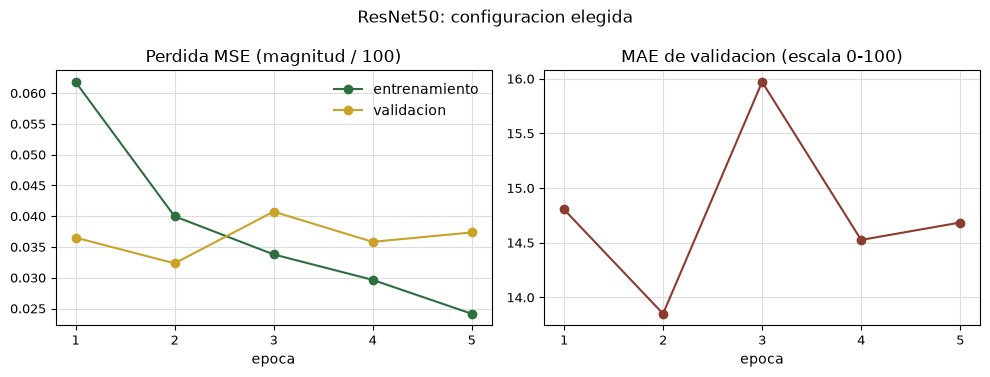

In [5]:
curva = pd.DataFrame([punto.model_dump() for punto in resultados.curva_entrenamiento])
fig, (ax_perdida, ax_mae) = plt.subplots(1, 2, figsize=(10, 3.8))
ax_perdida.plot(curva["epoca"], curva["perdida_entrenamiento"], marker="o", color=PALETA["principal"], label="entrenamiento")
ax_perdida.plot(curva["epoca"], curva["perdida_validacion"], marker="o", color=PALETA["secundario"], label="validacion")
ax_perdida.set_title("Perdida MSE (magnitud / 100)")
ax_perdida.set_xlabel("epoca")
ax_perdida.legend()
ax_mae.plot(curva["epoca"], curva["mae_validacion"], marker="o", color=PALETA["terciario"])
ax_mae.set_title("MAE de validacion (escala 0-100)")
ax_mae.set_xlabel("epoca")
for ax in (ax_perdida, ax_mae):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("ResNet50: configuracion elegida")
fig.tight_layout()
guardar_figura(fig, "06_curva_resnet")
curva.round(4)

## Resultados sobre la prueba

In [6]:
tabla = tabla_predicciones(resultados)
es_sequia = tabla["dano"] == "DR"
pd.DataFrame(
    {"DR": metricas(tabla.loc[es_sequia, "real"], tabla.loc[es_sequia, "predicho"]),
     "global": metricas(tabla["real"], tabla["predicho"])}
).T.round(3)

,n,mae,rmse,r2
DR,834.0,14.612,18.333,0.420
global,4628.0,2.633,7.783,0.826
